# Wald test vs. parallel-curves test vs. parallel-curves test on raw cells (legnini)

The same morphogen question as in `morphogen_example.ipynb` (Ctrl vs. SHH slides, expression as a function of the distance to SHH+ cells), answered three ways on the same gene panel and the same expression layer:

1. **Binned, classic Wald** (`test="wald"`): sliding windows (`bin_obs` default), tradeSeq-style functional Wald test on the posterior-predictive curves, p-values from an empirical null fitted to the gene panel.
2. **Binned, parallel-curves test** (`test="parallel"`): contiguous, cell-count-weighted bins; are the two condition curves parallel (differ only in level) up to a shape difference `tau`? p-values are per gene and do not depend on the panel.
3. **Raw cells, parallel-curves test with variational inference** (`use_binned=False, inference="advi"`): the same test on every cell instead of bins, with full-rank ADVI (Laplace start, Adam polish) instead of NUTS.

Each part shows the ranked gene table, a p-value histogram and a volcano plot.

**Before running:** all three fits cover the whole 88-gene panel with 4 worker processes. Part 3 does not store per-cell traces (the variational path leaves `mu` out), but it is still the heaviest part; set `GENES` to a short list for a trial run. The Wald test needs a panel (roughly 10+ genes) for its null, so keep that in mind when shortening.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data and anchor

As in the morphogen example: cells in the top percentile of SHH expression are the anchor, and every other cell gets its (normalised) distance to the closest SHH+ cell of its slide.

In [2]:
adata = sc.read_h5ad("/home/lehnerl/Arbeit/data/legnini23.h5ad")

shh = adata[:, "SHH"].X
shh = (shh.toarray() if hasattr(shh, "toarray") else np.asarray(shh)).ravel()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(adata, cluster_key="SHH+", groups="True", library_key="sample", covariates="condition")
adata.obsm["design_matrix"].head()

,SHH+,sample,True,True_raw,condition
0,False,slide1_A2-1,0.045167,97.930591,SHH
1,False,slide1_A2-1,0.404672,877.397221,SHH
2,True,slide1_A2-1,NaN,0.000000,SHH
3,False,slide1_A2-1,0.121246,262.882032,SHH
4,False,slide1_A2-1,0.149174,323.433256,SHH


## Settings

* `LAYER`: the Normal likelihood suits log-transformed data, so all three runs use `log1p_norm` (the morphogen example fits `.X`, i.e. normalised but not logged expression; set `LAYER = None` to do the same). The shape of a curve is judged on this scale.
* `TAU`: the smallest shape difference that counts for the parallel-curves test, in slope-equivalent units (the change of the condition gap across the anchor range). `0` tests exact parallelism.

In [3]:
LAYER = "log1p_norm"
GENES = list(adata.var_names)  # shorten for a trial run
N_WORKERS = 4
TAU = 0.1
timings = {}

## Helpers

In [4]:
def rank_table(stats, pvalue, statistic, columns):
    """Genes ordered by p-value, ties (e.g. p-values that underflow to 0) broken by the larger statistic."""
    table = stats.sort_values([pvalue, statistic], ascending=[True, False])[columns].copy()
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    return table


def qc_plots(stats, title):
    """p-value histogram next to the volcano plot (the plotting functions pick the columns of the test that ran)."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    dvg.pl.plot_pvalue_histogram(stats, ax=axes[0])
    dvg.pl.plot_volcano(stats, ax=axes[1], n_label=15)
    fig.suptitle(title)
    fig.tight_layout()
    return fig

## 1. Binned data, classic Wald test

Sliding windows of radius 0.02 around 51 grid points (`bin_obs` defaults), one P-spline GAM per gene sampled with NUTS. The Wald statistic compares the two posterior-predictive condition curves; p-values come from an empirical/Gamma null built from the lower 90% of the panel's statistics, so they depend on the panel. `empirical_pval` is the column the plots use.

In [5]:
t0 = time.perf_counter()
dvg.pp.bin_obs(adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50)
setup_wald = dvg.tl.setup_model(adata)
wald_stats, wald_preds, wald_curves = dvg.tl.fit_model(
    adata, setup_wald, n_workers=N_WORKERS, test="wald", inplace=False
)
timings["wald, binned, NUTS"] = time.perf_counter() - t0
print(f"{timings['wald, binned, NUTS']:.0f} s")

Fitting DiffSVG models:  50%|█████     | 44/88 [01:49<01:34,  2.15s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [03:37<00:00,  2.47s/it]

218 s


In [6]:
wald_table = rank_table(
    wald_stats,
    pvalue="empirical_pval",
    statistic="wald_stat",
    columns=["wald_stat", "wald_pval", "T", "empirical_pval", "empirical_pval_adj", "gamma_pval_adj", "integral"],
)
wald_table.head(25)

,rank,wald_stat,wald_pval,T,empirical_pval,empirical_pval_adj,gamma_pval_adj,integral
gene,,,,,,,,
PAX7,1,64789.337815,0.0,4.899368,0.0125,0.122222,2.344791e-13,-2.173056
NKX6.1,2,36355.352109,0.0,4.637764,0.0125,0.122222,6.057377e-13,2.100781
Circ.RMST,3,18067.342831,0.0,1.891341,0.0125,0.122222,1.324593e-05,-1.329157
IRX3,4,17178.939673,0.0,1.881162,0.0125,0.122222,1.324593e-05,-1.351597
NEUROG2,5,8311.761154,0.0,0.534043,0.0125,0.122222,7.598402e-02,0.640617
GLI3,6,4422.841409,0.0,0.685908,0.0125,0.122222,3.103943e-02,-0.810690
GLI2,7,3851.842681,0.0,0.458736,0.0125,0.122222,1.126154e-01,-0.639237
PTPRZ1,8,3603.970582,0.0,0.271268,0.0125,0.122222,3.541163e-01,-0.482738
PAX6,9,2683.512943,0.0,0.431890,0.0125,0.122222,1.201169e-01,-0.551438


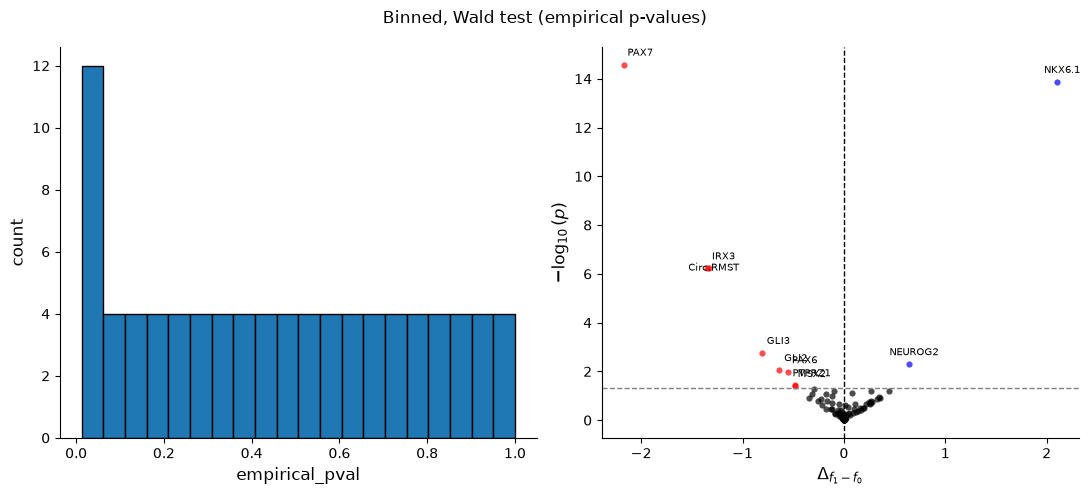

In [7]:
qc_plots(wald_stats, "Binned, Wald test (empirical p-values)");

## 2. Binned data, parallel-curves test

Contiguous bins (`window_radius=None`): every cell counts once, rows are weighted by their cell count and the cell-level noise is recovered, so the binned fit carries the same information as a fit on the cells. The test asks whether the curves are parallel up to `TAU` and is calibrated per gene (no panel needed). Columns: `shape_diff` (distance from parallel, in slope-equivalent units), `slope_diff` (linear trend of the gap), `integral` (level difference).

Cells of all slides are pooled here, so the p-values do not include the variation *between* slides. Read the ranking and the effect sizes first; many p-values will be small on this data.

In [8]:
t0 = time.perf_counter()
dvg.pp.bin_obs(adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None)
setup_parallel = dvg.tl.setup_model(adata)
par_stats, par_preds, par_curves = dvg.tl.fit_model(
    adata, setup_parallel, n_workers=N_WORKERS, test="parallel", tau=TAU, inplace=False
)
timings["parallel, binned, NUTS"] = time.perf_counter() - t0
print(f"{timings['parallel, binned, NUTS']:.0f} s")

Fitting DiffSVG models:   1%|          | 1/88 [00:10<15:34, 10.75s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [04:51<00:00,  3.31s/it]

291 s


In [9]:
PARALLEL_COLUMNS = [
    "shape_diff", "slope_diff", "slope_diff_ci_low", "slope_diff_ci_high",
    "parallel_stat", "parallel_pval", "parallel_pval_adj", "integral",
]  # fmt: skip
par_table = rank_table(par_stats, pvalue="parallel_pval", statistic="parallel_stat", columns=PARALLEL_COLUMNS)
par_table.head(25)

,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral
gene,,,,,,,,,
PAX7,1,1.746356,-1.041075,-1.093982,-0.987274,6115.673690,0.000000e+00,0.000000e+00,-2.169751
HHIP,2,1.459576,1.013742,0.951136,1.075811,3888.414328,0.000000e+00,0.000000e+00,-0.100602
GLI1,3,1.269972,0.940870,0.882106,1.001639,3056.893836,0.000000e+00,0.000000e+00,0.270361
FOXA2,4,0.963450,0.466985,0.425357,0.508207,1860.146792,0.000000e+00,0.000000e+00,-0.001717
DBX1,5,1.288665,0.697092,0.610467,0.784378,1812.570653,0.000000e+00,0.000000e+00,-0.177798
DBX2,6,0.933460,0.483309,0.418054,0.550233,1797.747138,0.000000e+00,0.000000e+00,-0.308854
AC129492.1,7,1.272736,-1.072202,-1.156954,-0.986905,1583.926769,2.363610e-280,2.971396e-279,-0.115404
PTCH1,8,1.427447,0.498513,0.396102,0.593875,1412.993757,9.795775e-253,1.077535e-251,0.079050
FOS,9,0.969881,-0.612994,-0.682366,-0.544742,1455.995142,9.909216e-242,9.689011e-241,-0.050028


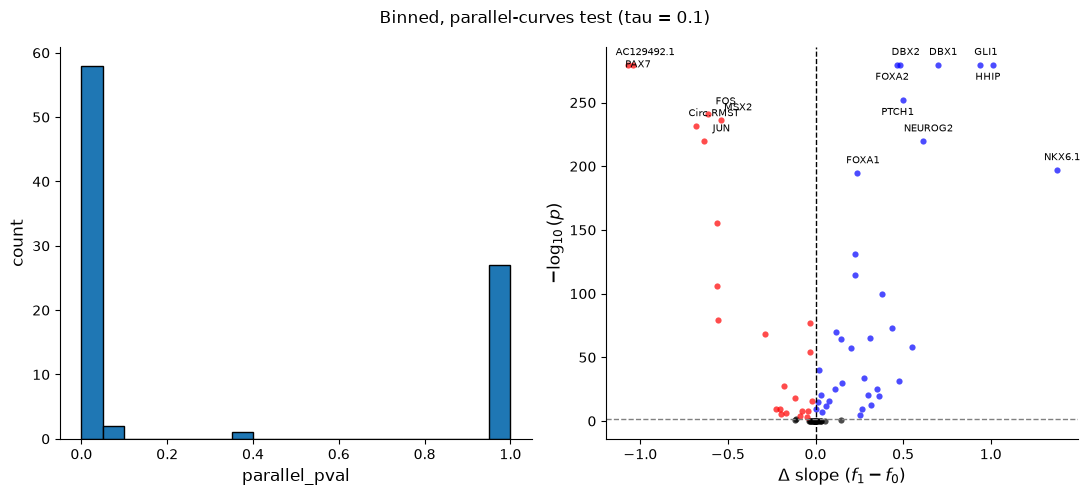

In [10]:
qc_plots(par_stats, f"Binned, parallel-curves test (tau = {TAU})");

## 3. Raw cells, parallel-curves test with variational inference

The same model and test, fitted on every cell (`use_binned=False`) with full-rank ADVI: a Laplace approximation as the starting point, then Adam polishing (`inference="advi"`). The binning from part 2 is only used for the spline basis and the prediction grid.

Plain ADVI does not work for this test (see `.claude/advi_plan.md`); the Laplace start is what makes it usable. Two diagnostics check each gene's fit against the true posterior: `vi_khat` (below ~0.7) and `vi_ess` (above ~0.5) mean the covariance the test is built on can be trusted. Genes outside that range should not be read.

In [11]:
t0 = time.perf_counter()
vi_stats, vi_preds, vi_curves = dvg.tl.fit_model(
    adata,
    setup_parallel,
    n_workers=N_WORKERS,
    use_binned=False,
    inference="advi",
    test="parallel",
    tau=TAU,
    inplace=False,
)
timings["parallel, cells, ADVI"] = time.perf_counter() - t0
print(f"{timings['parallel, cells, ADVI']:.0f} s")

Fitting DiffSVG models:  47%|████▋     | 41/88 [03:35<03:21,  4.29s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [07:01<00:00,  4.79s/it]

422 s


In [12]:
vi_stats["vi_trusted"] = (vi_stats["vi_khat"] < 0.7) & (vi_stats["vi_ess"] > 0.5)
print(f"{vi_stats['vi_trusted'].sum()} of {len(vi_stats)} genes pass the variational diagnostics")
vi_table = rank_table(
    vi_stats,
    pvalue="parallel_pval",
    statistic="parallel_stat",
    columns=[*PARALLEL_COLUMNS, "vi_khat", "vi_ess", "vi_trusted"],
)
vi_table.head(25)

85 of 88 genes pass the variational diagnostics


,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,vi_trusted
gene,,,,,,,,,,,,
PAX7,1,1.771784,-1.049524,-1.102262,-0.999123,6261.889601,0.000000e+00,0.000000e+00,-2.167183,0.207713,0.775775,True
HHIP,2,1.470284,1.016162,0.954145,1.075549,3841.301188,0.000000e+00,0.000000e+00,-0.100362,0.229310,0.784461,True
GLI1,3,1.275424,0.939257,0.879250,0.996867,3141.810411,0.000000e+00,0.000000e+00,0.268184,0.226889,0.782856,True
DBX1,4,1.289429,0.696876,0.609798,0.780463,1936.617573,0.000000e+00,0.000000e+00,-0.173251,0.173907,0.802866,True
DBX2,5,0.934258,0.483018,0.417396,0.545941,1909.282850,0.000000e+00,0.000000e+00,-0.308602,0.242377,0.787491,True
FOXA2,6,1.010627,0.478235,0.437536,0.517036,1878.719035,0.000000e+00,0.000000e+00,-0.004395,0.222257,0.763086,True
AC129492.1,7,1.272180,-1.069983,-1.157454,-0.986010,1563.338684,1.217412e-276,1.530461e-275,-0.117657,0.172541,0.803113,True
PTCH1,8,1.440611,0.501819,0.405175,0.594605,1471.718945,6.243663e-264,6.868029e-263,0.084623,0.147752,0.808582,True
FOS,9,0.970804,-0.615020,-0.685128,-0.547873,1448.503305,1.931668e-240,1.888742e-239,-0.050897,0.237103,0.790818,True


In [13]:
vi_stats.loc[~vi_stats["vi_trusted"], ["vi_khat", "vi_ess", "shape_diff", "parallel_stat"]]

,vi_khat,vi_ess,shape_diff,parallel_stat
gene,,,,
NKX2.1,0.541741,0.060924,0.001497,1.325269
TBR1,0.460977,0.115861,0.005321,6.707058
TREM2,2.660310,0.012767,0.000825,2.530723


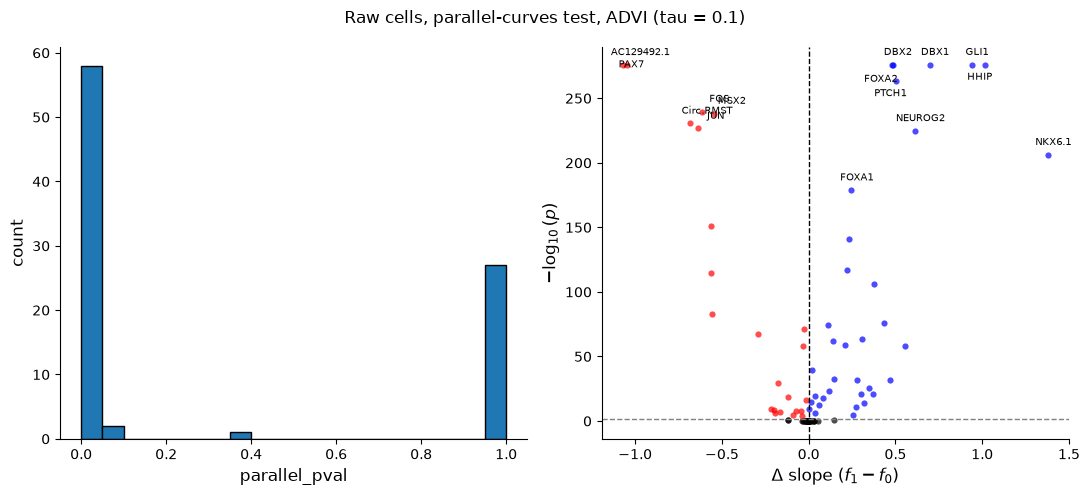

In [14]:
qc_plots(vi_stats, f"Raw cells, parallel-curves test, ADVI (tau = {TAU})");

## Comparison

How much do the three rankings agree? Spearman correlation of the gene ranks, the overlap of the top 20, and the shape difference estimated from bins vs. from cells.

In [15]:
ranks = pd.DataFrame(
    {
        "wald (binned)": wald_table["rank"],
        "parallel (binned)": par_table["rank"],
        "parallel (cells, ADVI)": vi_table["rank"],
    }
)
print("Spearman correlation of the ranks")
display(ranks.corr(method="spearman").round(3))

top = {name: set(ranks[name].nsmallest(20).index) for name in ranks}
overlap = pd.DataFrame({a: {b: len(top[a] & top[b]) for b in top} for a in top})
print("Overlap of the top 20 genes")
display(overlap)

pd.Series(timings, name="seconds").round(0).to_frame()

Spearman correlation of the ranks


,wald (binned),parallel (binned),"parallel (cells, ADVI)"
wald (binned),1.000,0.865,0.866
parallel (binned),0.865,1.000,0.999
"parallel (cells, ADVI)",0.866,0.999,1.000


Overlap of the top 20 genes


,wald (binned),parallel (binned),"parallel (cells, ADVI)"
wald (binned),20,13,13
parallel (binned),13,20,20
"parallel (cells, ADVI)",13,20,20


,seconds
"wald, binned, NUTS",218.0
"parallel, binned, NUTS",291.0
"parallel, cells, ADVI",422.0


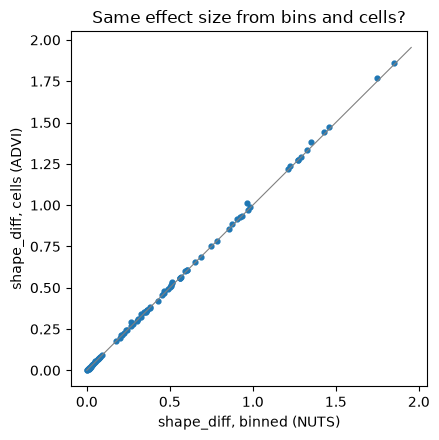

In [16]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(par_stats["shape_diff"], vi_stats.loc[par_stats.index, "shape_diff"], s=12)
lim = float(max(par_stats["shape_diff"].max(), vi_stats["shape_diff"].max())) * 1.05
ax.plot([0, lim], [0, lim], color="grey", lw=0.8)
ax.set(xlabel="shape_diff, binned (NUTS)", ylabel="shape_diff, cells (ADVI)", title="Same effect size from bins and cells?")
fig.tight_layout()